In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker



In [2]:
df = pd.read_csv(r"C:\Users\Ayobami Adeyemo\Downloads\clean.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18857 entries, 0 to 18856
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ConvertedCompYearly     18857 non-null  float64
 1   Country                 18857 non-null  str    
 2   WorkExp                 18857 non-null  float64
 3   YearsCode               18857 non-null  float64
 4   EdLevel                 18857 non-null  str    
 5   Age                     18857 non-null  str    
 6   DevType                 18857 non-null  str    
 7   Employment              18857 non-null  str    
 8   OrgSize                 18857 non-null  str    
 9   RemoteWork              18857 non-null  str    
 10  Industry                18857 non-null  str    
 11  ICorPM                  18857 non-null  str    
 12  LanguageHaveWorkedWith  18857 non-null  str    
dtypes: float64(3), str(10)
memory usage: 6.4 MB


In [4]:
df.describe()

,ConvertedCompYearly,WorkExp,YearsCode
count,18857.000000,18857.000000,18857.000000
mean,94405.894204,13.432784,18.181312
std,67500.564872,9.638208,10.590943
min,1011.000000,1.000000,1.000000
25%,47334.000000,6.000000,10.000000
50%,81210.000000,11.000000,15.000000
75%,125296.000000,19.000000,25.000000
max,445000.000000,100.000000,100.000000


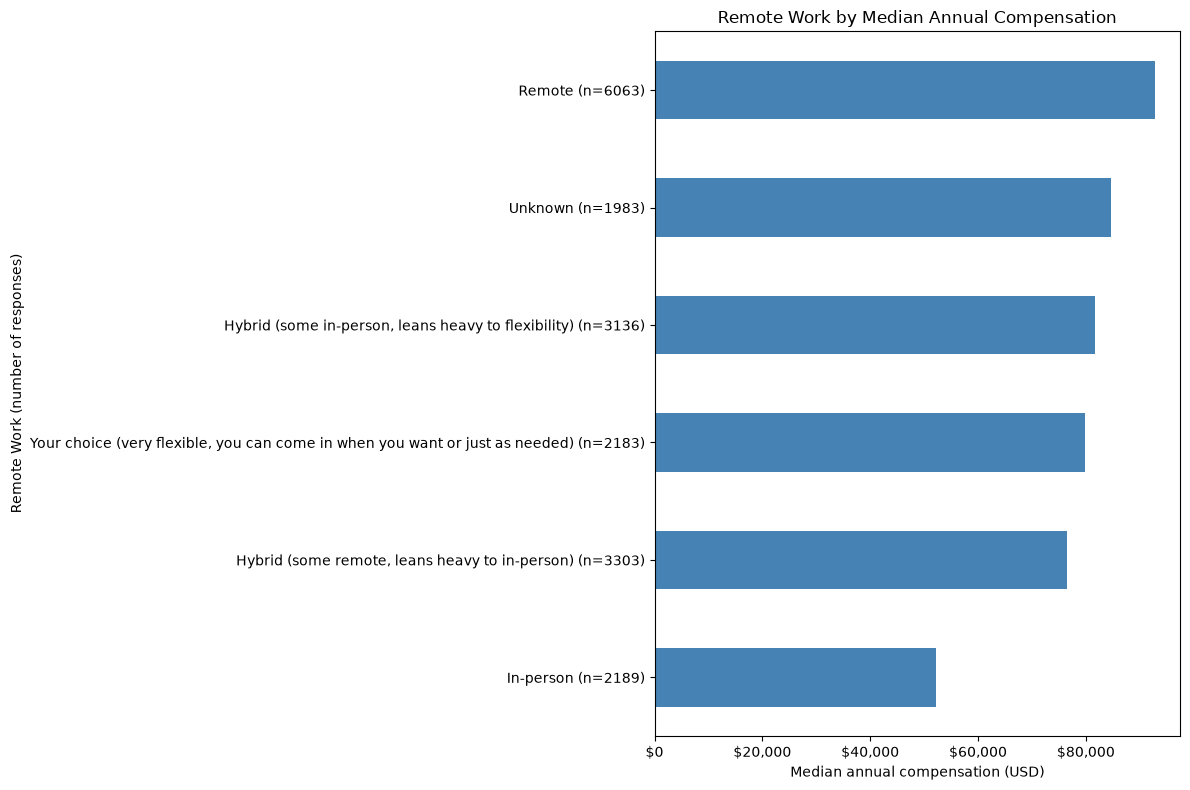

In [5]:
# Keep rows with both a RemoteWork and compensation
comp = df[["RemoteWork", "ConvertedCompYearly"]].dropna()

# Summarize compensation and response counts by country
summary = comp.groupby("RemoteWork")["ConvertedCompYearly"].agg(
    median="median",
    responses="count"
)

# Exclude countries with very few responses, then select the top 10
#summary = summary[summary["responses"] >= 30].nlargest(10, "median")
summary = summary.sort_values("median")

# Include response counts in the country labels
labels = [
    f"{country} (n={count})"
    for country, count in zip(summary.index, summary["responses"])
]

ax = summary["median"].plot(
    kind="barh",
    figsize=(12, 8),
    color="steelblue"
)

ax.set_yticklabels(labels)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))

plt.xlabel("Median annual compensation (USD)")
plt.ylabel("Remote Work (number of responses)")
plt.title("Remote Work by Median Annual Compensation")
plt.tight_layout()
plt.show()

,responses,median,q1,q3
RemoteWork,,,,
In-person,2189,"$52,207","$22,368","$96,724"
"Hybrid (some remote, leans heavy to in-person)",3303,"$76,570","$48,726","$116,015"
"Your choice (very flexible, you can come in when you want or just as needed)",2183,"$79,779","$52,207","$113,173"
"Hybrid (some in-person, leans heavy to flexibility)",3136,"$81,685","$53,367","$117,175"
Unknown,1983,"$84,599","$51,058","$130,992"
Remote,6063,"$92,812","$52,207","$150,000"


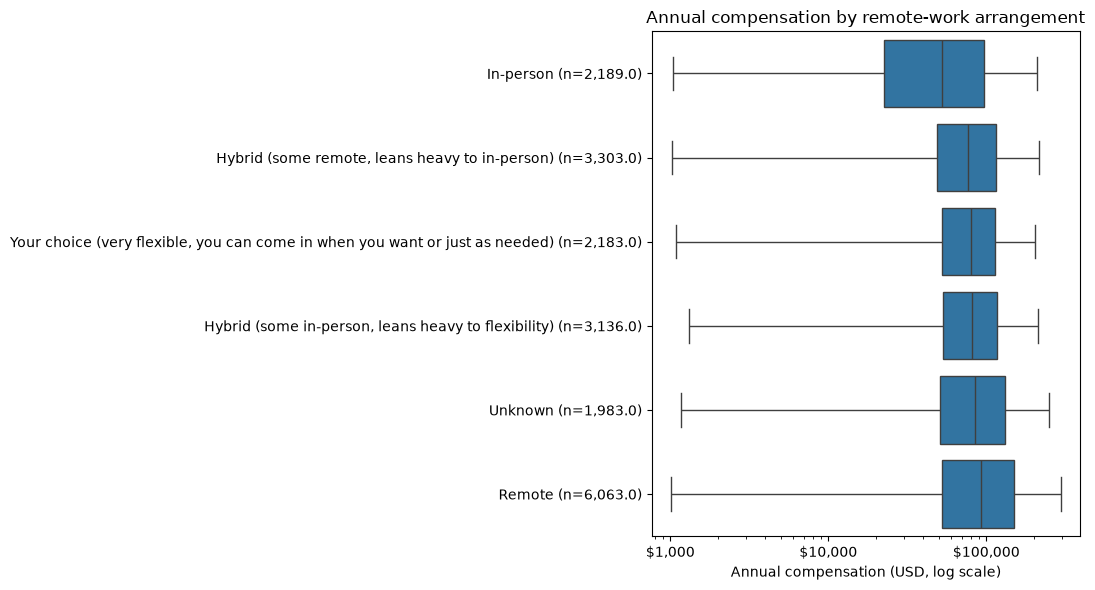

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Keep rows with a remote-work category and a valid, positive annual compensation
comp = df[["RemoteWork", "ConvertedCompYearly"]].copy()
comp["ConvertedCompYearly"] = pd.to_numeric(
    comp["ConvertedCompYearly"], errors="coerce"
)
comp = comp.dropna()
comp = comp[comp["ConvertedCompYearly"] > 0]

# Summarize sample size and compensation distribution for each category
summary = (
    comp.groupby("RemoteWork", observed=True)["ConvertedCompYearly"]
    .agg(
        responses="count",
        median="median",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
    .sort_values("median")
)

display(summary.style.format({
    "median": "${:,.0f}",
    "q1": "${:,.0f}",
    "q3": "${:,.0f}",
}))

# Add sample sizes to category labels
labels = {
    category: f"{category} (n={row.responses:,})"
    for category, row in summary.iterrows()
}
comp["RemoteWorkLabel"] = comp["RemoteWork"].map(labels)
order = [labels[category] for category in summary.index]

# Compare distributions; a log scale helps show the spread of salaries
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=comp,
    x="ConvertedCompYearly",
    y="RemoteWorkLabel",
    order=order,
    showfliers=False,
    ax=ax,
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set(
    title="Annual compensation by remote-work arrangement",
    xlabel="Annual compensation (USD, log scale)",
    ylabel="",
)
plt.tight_layout()
plt.show()

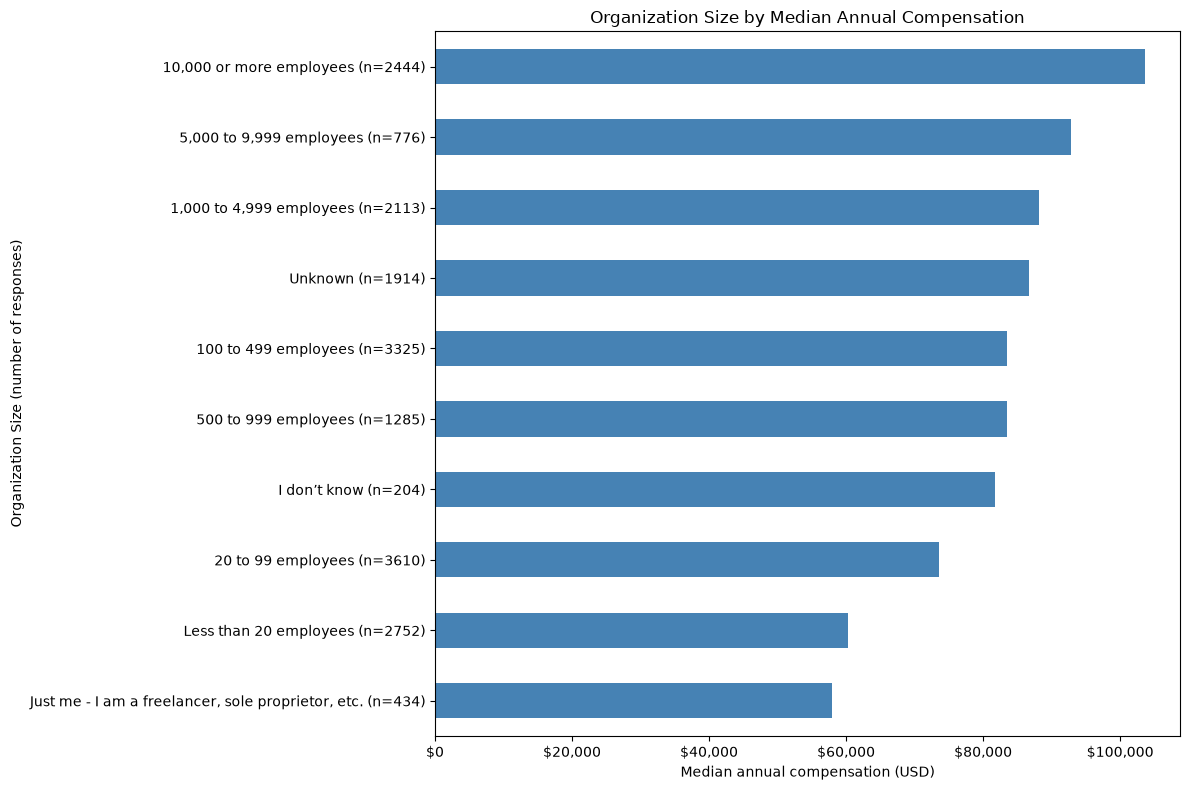

In [7]:
# Keep rows with both a RemoteWork and compensation
comp = df[["OrgSize", "ConvertedCompYearly"]].dropna()

# Summarize compensation and response counts by country
summary = comp.groupby("OrgSize")["ConvertedCompYearly"].agg(
    median="median",
    responses="count"
)

# Exclude countries with very few responses, then select the top 10
#summary = summary[summary["responses"] >= 30].nlargest(10, "median")
summary = summary.sort_values("median")

# Include response counts in the country labels
labels = [
    f"{country} (n={count})"
    for country, count in zip(summary.index, summary["responses"])
]

ax = summary["median"].plot(
    kind="barh",
    figsize=(12, 8),
    color="steelblue"
)

ax.set_yticklabels(labels)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))

plt.xlabel("Median annual compensation (USD)")
plt.ylabel("Organization Size (number of responses)")
plt.title("Organization Size by Median Annual Compensation")
plt.tight_layout()
plt.show()

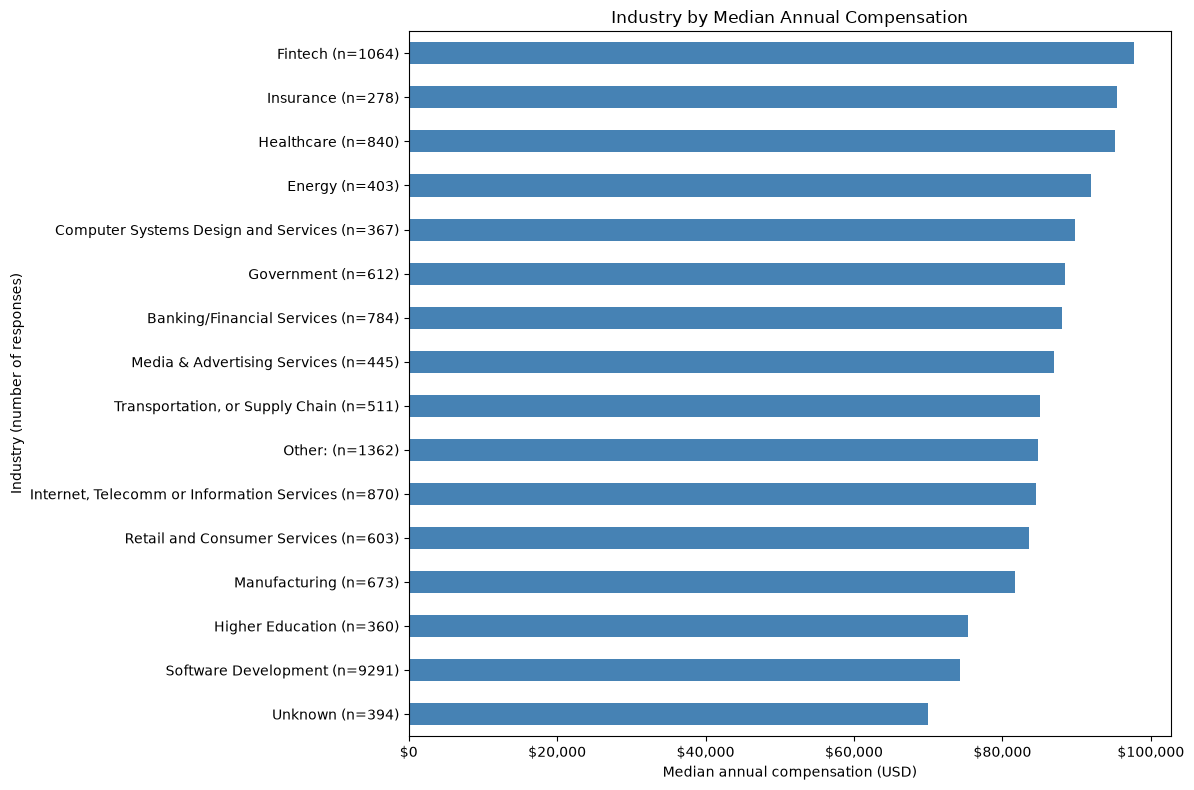

In [8]:
# Keep rows with both a RemoteWork and compensation
comp = df[["Industry", "ConvertedCompYearly"]].dropna()

# Summarize compensation and response counts by country
summary = comp.groupby("Industry")["ConvertedCompYearly"].agg(
    median="median",
    responses="count"
)

# Exclude countries with very few responses, then select the top 10
#summary = summary[summary["responses"] >= 30].nlargest(10, "median")
summary = summary.sort_values("median")

# Include response counts in the country labels
labels = [
    f"{country} (n={count})"
    for country, count in zip(summary.index, summary["responses"])
]

ax = summary["median"].plot(
    kind="barh",
    figsize=(12, 8),
    color="steelblue"
)

ax.set_yticklabels(labels)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))

plt.xlabel("Median annual compensation (USD)")
plt.ylabel("Industry (number of responses)")
plt.title("Industry by Median Annual Compensation")
plt.tight_layout()
plt.show()